KNN (number of neighbours,nearest, neighbour)

In [1]:
import pandas as pd
import seaborn as sns

In [2]:
df=sns.load_dataset("titanic")
print(df.shape)
df.head()

(891, 15)


,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [3]:
df = df[["survived", "pclass", "sex", "age", "sibsp", "parch", "fare"]].copy()

df["age"] = df["age"].fillna(df["age"].median())
df["sex"] = df["sex"].map({"male": 0, "female": 1})

print(df.isnull().sum())

survived    0
pclass      0
sex         0
age         0
sibsp       0
parch       0
fare        0
dtype: int64


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("survived", axis=1)
y = df["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

In [5]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)

y_pred = knn.predict(X_test_s)

print("Train accuracy:", knn.score(X_train_s, y_train))
print("Test accuracy:", accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

Train accuracy: 0.8637640449438202
Test accuracy: 0.8268156424581006
[[97 13]
 [18 51]]
              precision    recall  f1-score   support

           0       0.84      0.88      0.86       110
           1       0.80      0.74      0.77        69

    accuracy                           0.83       179
   macro avg       0.82      0.81      0.81       179
weighted avg       0.83      0.83      0.83       179



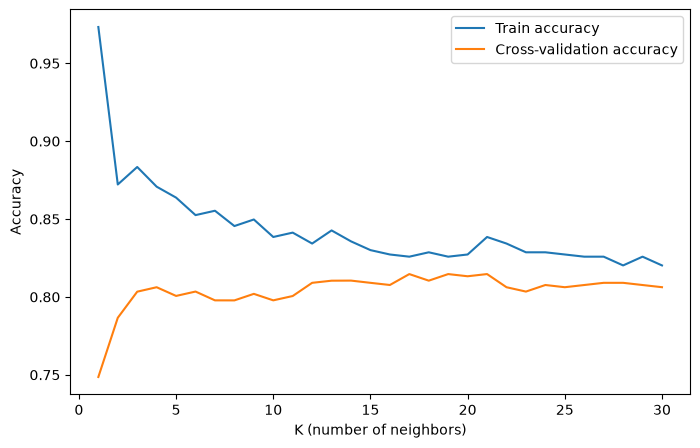

Best K: 21 | CV accuracy: 0.8146754653796906


In [6]:
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score

ks = list(range(1, 31))
train_acc, cv_acc = [], []

for k in ks:
    pipe = Pipeline([
        ("scaler", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k))
    ])
    pipe.fit(X_train, y_train)
    train_acc.append(pipe.score(X_train, y_train))
    cv_acc.append(cross_val_score(pipe, X_train, y_train, cv=5).mean())

plt.figure(figsize=(8, 5))
plt.plot(ks, train_acc, label="Train accuracy")
plt.plot(ks, cv_acc, label="Cross-validation accuracy")
plt.xlabel("K (number of neighbors)")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

best_k = ks[cv_acc.index(max(cv_acc))]
print("Best K:", best_k, "| CV accuracy:", max(cv_acc))

In [7]:
from sklearn.model_selection import GridSearchCV

pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier())
])

param_grid = {
    "knn__n_neighbors": list(range(1, 31)),
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan"]
}

grid = GridSearchCV(pipe, param_grid, cv=5, scoring="accuracy")
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV score:", grid.best_score_)
print("Test accuracy:", grid.score(X_test, y_test))

Best params: {'knn__metric': 'manhattan', 'knn__n_neighbors': 19, 'knn__weights': 'uniform'}
Best CV score: 0.8216586230670739
Test accuracy: 0.8100558659217877


In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

lr_pipe = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(C=0.1, max_iter=1000))
])
knn_pipe = grid.best_estimator_

for name, p in [("Logistic Regression", lr_pipe), ("KNN (tuned)", knn_pipe)]:
    s = cross_val_score(p, X_train, y_train, cv=5)
    print(f"{name}: mean={s.mean():.4f}, std={s.std():.4f}")

Logistic Regression: mean=0.7978, std=0.0243
KNN (tuned): mean=0.8217, std=0.0166


In [9]:
y_pred = grid.predict(X_test)
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

[[100  10]
 [ 24  45]]
              precision    recall  f1-score   support

           0       0.81      0.91      0.85       110
           1       0.82      0.65      0.73        69

    accuracy                           0.81       179
   macro avg       0.81      0.78      0.79       179
weighted avg       0.81      0.81      0.81       179

